# Cross-task decoding

**NeurodeskEDU working draft — public educational data, N = 67.**

Train a linear classifier to distinguish human from computer context in Shared Reward, then evaluate transfer to Trust in unseen participants. Start from precomputed signed outcome COPEs; no fMRI preprocessing or first-level GLM estimation is required.

**Draft prepared for:** David V. Smith. Jacob and Riccardo will review and test the tutorial; final authorship will reflect actual contributions.  
**Updated:** October 28, 2026.  
**Licenses:** MIT for code; CC BY 4.0 for original explanations; CC0 for the separately published map archive. The external template and software retain their upstream terms.  
**Audience:** basic Python and introductory fMRI/GLM knowledge.  
**Download:** approximately 310 MB once, then cached. Allow roughly 1.5 GB free disk space; numerical features occupy about 91 MB, with additional memory used during fitting. Network speed dominates the first run.

<details><summary>AI assistance and review status</summary>
OpenAI Codex assisted with code and explanations. The public-data workflow passed a fresh Zenodo download, exact mask reconstruction, and full execution in an isolated local environment built from the pinned requirements. The enhanced workflow also passed on Neurodesk Play (Neurodesktop 2026-10-07, Python 3.13.15), including all 999 permutation refits and static figures. Human teaching/scientific review remains before submission to NeurodeskEDU. This draft is independent of the parent paper's model selection and sealed validation sample.
</details>


## What you will learn

1. Distinguish a signed effect estimate (COPE) from a z-statistic and a decoder coefficient.
2. Keep each participant's conditions and tasks in a single cross-validation fold.
3. Compare within-task prediction and cross-task transfer on the same held-out people.
4. Distinguish bootstrap intervals from participant-blocked permutation tests.
5. Plot decoder coefficients and a Haufe-style forward pattern without treating either as a causal brain map.

**The data boundary:** the source snapshot is the public N=114 release, OpenNeuro **ds005123 v1.0.0**. The exported tutorial subset has **67 eligible participants and 804 outcome maps** after exclusion of the full protected validation pool, existing QC and complete-input checks. These decisions occurred before export. The tutorial consumes only the released maps; it never loads private membership lists, main-project caches, frozen paper models or reserved validation images.

**Why exclude people whose raw data are already public?** Public availability does not determine eligibility for model development. A prespecified validation cohort is reserved for the paper and is excluded before this tutorial loads any images. Its detailed membership stays outside the teaching bundle. The temporary test folds used below are cross-validation folds within the permitted educational subset; they are not that reserved cohort. Merely reporting that a cohort is held out does not score it or disclose its results.

## Citations and resources

- Original dataset: [OpenNeuro ds005123 v1.0.0](https://doi.org/10.18112/openneuro.ds005123.v1.0.0), whose metadata specifies CC0. Cite the corresponding [data paper](https://pubmed.ncbi.nlm.nih.gov/39252767/) as well.
- Derived educational maps: **[Zenodo v1.0.0: 10.5281/zenodo.23718599](https://doi.org/10.5281/zenodo.23718599)**. The release must document source contrast names/weights, outcome phase, retained run strategy, preprocessing, QC, grid, independent mask source and file checksums.
- [Neurodesk citation guidance](https://neurodesk.org/overview/how-to-cite-us/) and [NeurodeskEDU template](https://github.com/neurodesk/neurodeskedu/blob/main/books/examples/template.ipynb).
- Scikit-learn: [Pedregosa et al., 2011](https://jmlr.org/papers/v12/pedregosa11a.html); [NIfTI handling with NiBabel](https://nipy.org/nibabel/).
- Forward-pattern interpretation: [Haufe et al., 2014](https://doi.org/10.1016/j.neuroimage.2013.10.067).

The default public mode uses the DOI-pinned 67-person educational subset. An optional, clearly labelled synthetic mode checks code flow without study data. Its simulated results must not be interpreted as human-data findings.
- Permutation testing: [scikit-learn reference](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.permutation_test_score.html); this notebook explicitly implements paired participant swaps across both tasks, with full model refitting.


## 1. Environment and fixed choices

Start with `bash run_tutorial.sh --setup-play` in a Neurodesk Play terminal, then select **Social context (pinned)** as this notebook's kernel. On a laptop, `bash run_tutorial.sh` opens an isolated JupyterLab. Both install the exact versions in `requirements.txt`; neither changes the base Python environment.

Neurodesk's `ml load tool/version` commands select versioned **application containers**. This notebook analyzes already estimated COPEs using Python packages; it does not run FSL, so no FSL module is needed. The audit below runs `ml list` when available and records the Neurodesktop image plus the package versions at the end. In a tutorial that actually ran FEAT, the appropriate versioned FSL module would also need to be loaded.

The classifier, mask, five participant folds, 999 permutations and display coordinates are specified below. Do not repeatedly change these choices to improve accuracy. This educational analysis is separate from candidate selection for the paper.

In [1]:
from pathlib import Path
import hashlib, importlib.metadata, importlib.util, itertools, json, os, platform
import shutil, stat, subprocess, tempfile, time, urllib.parse, urllib.request, warnings, zipfile
from threadpoolctl import threadpool_limits
from joblib import Parallel, delayed, parallel_config
from sklearn.exceptions import ConvergenceWarning
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.svm import LinearSVC
from IPython.display import display

MODE = "public"  # Use "synthetic" for the explicitly labelled simulated fixture.
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs" / MODE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED, N_FOLDS, C = 20261027, 5, 1.0
N_PERMUTATIONS, N_WORKERS = 999, min(4, os.cpu_count() or 1)
# Avoid nested BLAS threads; parallel work is across complete permutation refits.
thread_limit = threadpool_limits(limits=1)
warnings.filterwarnings("error", category=ConvergenceWarning)
TASKS = ("sharedreward", "trust")
PARTNERS = ("computer", "friend", "stranger")
VALENCES = ("positive", "negative")
STARTED = time.perf_counter()
LABEL = "SYNTHETIC FIXTURE — not human results" if MODE == "synthetic" else "Public educational subset"
assert MODE in ("synthetic", "public")
print(LABEL)

Public educational subset


In [2]:
try:
    audit = subprocess.run(["bash", "-lc", "if type ml >/dev/null 2>&1; then ml list 2>&1; "
                            "else echo 'ml unavailable: outside the Neurodesk module shell'; fi"],
                           capture_output=True, text=True, check=True)
    MODULE_AUDIT = audit.stdout.strip()
except (FileNotFoundError, subprocess.CalledProcessError) as error:
    MODULE_AUDIT = f"Module shell unavailable: {type(error).__name__}"
IMAGE_VERSION = {key: os.environ[key] for key in ("JUPYTER_IMAGE", "NEURODESKTOP_VERSION") if key in os.environ}
print("Python", platform.python_version(), "|", IMAGE_VERSION or "Outside Neurodesk")
print(MODULE_AUDIT)
print(f"Fixed permutation count: {N_PERMUTATIONS}; at most {N_WORKERS} worker processes")

Python 3.13.5 | Outside Neurodesk
ml unavailable: outside the Neurodesk module shell
Fixed permutation count: 999; at most 4 worker processes


## 2. Retrieve a fixed data release

For real data, the notebook downloads **one frozen, checksum-verified archive**. It does not discover data from a mutable directory or scan a local research checkout. The archive contains 12 COPEs per person: two tasks × three partners × two valences. A small metadata manifest accompanies the maps. The independent fixed TemplateFlow mask is retrieved separately from its original provider, checksum-verified and resampled using a predefined rule; its voxels must match the reviewed reference mask exactly. It is not redistributed or relicensed in the Zenodo archive.

**Public mode is the default.** The reviewed DOI, version-specific file URL, SHA256, sample size and export-audit evidence are pinned in `data_release.json`. A failed download or checksum stops execution; it never switches to synthetic data. Set `MODE = "synthetic"` explicitly only when you want the simulated fixture.

In [3]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def public_release(config):
    assert config["status"] == "published", "Publish and review the educational release first."
    assert config["source_dataset"] == "ds005123" and config["source_version"] == "1.0.0"
    assert config["derivative_doi"] and config["expected_n"] > N_FOLDS
    audit_keys = {"public_release_only", "sealed_N50_excluded", "external_validation_excluded", "qc_and_complete_maps_verified"}
    assert all(config["membership_audit"].get(key) is True for key in audit_keys), "Curator membership/QC audit is incomplete."
    assert config["mask_provenance"]["kind"] == "independent_template"
    assert config["mask_provenance"]["description"] and config["mask_provenance"]["source_url"]
    url, expected = config["archive_url"], config["archive_sha256"]
    assert urllib.parse.urlsplit(url).scheme == "https"
    assert urllib.parse.urlsplit(url).hostname == "zenodo.org", "Use the reviewed Zenodo record URL."
    assert len(expected) == 64 and all(c in "0123456789abcdef" for c in expected)
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    archive = DATA_DIR / (expected + ".zip")
    if not archive.exists():
        temporary = archive.with_suffix(".part")
        try:
            with urllib.request.urlopen(url, timeout=90) as source, temporary.open("wb") as target:
                total = 0
                for block in iter(lambda: source.read(1024 * 1024), b""):
                    total += len(block)
                    assert total <= config["max_download_bytes"], "Download exceeds reviewed limit."
                    target.write(block)
            assert sha256(temporary) == expected, "Archive checksum mismatch."
            temporary.replace(archive)
        finally:
            temporary.unlink(missing_ok=True)
    assert sha256(archive) == expected, "Cached archive changed."
    destination = DATA_DIR / ("public-" + expected[:16])
    assert not destination.is_symlink()
    if destination.exists():
        assert all(not p.is_symlink() for p in destination.rglob("*")), "Symlink in cached extraction."
    with zipfile.ZipFile(archive) as z:
        assert sum(i.file_size for i in z.infolist()) <= config["max_uncompressed_bytes"]
        for info in z.infolist():
            parts = Path(info.filename).parts
            assert not Path(info.filename).is_absolute() and ".." not in parts
            assert not stat.S_ISLNK(info.external_attr >> 16), "Archive symlinks are not allowed."
        z.extractall(destination)
    print("Derivative DOI:", config["derivative_doi"])
    return destination, config["expected_n"]

def reconstruct_external_mask(destination):
    # Reference asset is fetched from its provider, not redistributed in Zenodo.
    from nibabel.processing import resample_from_to
    metadata = json.loads((destination / "dataset_description.json").read_text())
    assert metadata["MaskDistribution"] == "external_reference_only"
    provenance = metadata["MaskProvenance"]
    url, expected = provenance["template_download_url"], provenance["template_sha256"]
    assert url == "https://templateflow.s3.amazonaws.com/tpl-MNI152NLin6Asym/tpl-MNI152NLin6Asym_res-02_desc-brain_mask.nii.gz"
    assert len(expected) == 64 and all(c in "0123456789abcdef" for c in expected)
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    template_path = DATA_DIR / ("template-" + expected + ".nii.gz")
    if not template_path.exists():
        with urllib.request.urlopen(url, timeout=90) as stream:
            payload = stream.read(5_000_001)
        assert len(payload) <= 5_000_000 and hashlib.sha256(payload).hexdigest() == expected
        template_path.write_bytes(payload)
    assert sha256(template_path) == expected, "External template checksum mismatch."
    template = nib.load(template_path)
    values = template.get_fdata()
    assert values.ndim == 3 and np.isfinite(values).all() and np.isin(values, [0, 1]).all()
    row = pd.read_csv(destination / "manifest.csv").iloc[0]
    reference_path = (destination / row.path).resolve()
    assert reference_path.is_relative_to(destination.resolve())
    reference = nib.load(reference_path)  # Common grid only; no participant intensities.
    resampled = resample_from_to(template, (reference.shape, reference.affine), order=0, mode="constant", cval=0)
    mask = resampled.get_fdata().astype("uint8")
    assert mask.any() and hashlib.sha256(mask.tobytes(order="C")).hexdigest() == provenance["expected_resampled_mask_data_sha256"]
    image = nib.Nifti1Image(mask, reference.affine)
    image.header.set_xyzt_units("mm")
    nib.save(image, destination / "mask.nii.gz")
    print("Independent reference mask reconstructed and verified; upstream terms apply to that external resource.")


### Load the selected mode; optional synthetic fixture

The fixture creates an independently specified spherical mask and simulated condition maps with shared signal and noise. It contains no study participants. The fixed seed makes runs repeatable; it is not evidence that the classifier will perform well on real data.

In [4]:
def synthetic_release():
    destination = DATA_DIR / "synthetic-v1"
    destination.mkdir(parents=True, exist_ok=True)
    shape = (16, 16, 12)
    affine = np.diag([3.0, 3.0, 3.0, 1.0])
    affine[:3, 3] = [-24, -24, -18]
    grid = np.indices(shape).astype(float)
    sphere = sum(((grid[k] - (shape[k] - 1) / 2) / (shape[k] / 2)) ** 2 for k in range(3)) < 0.70
    signal = np.sin(grid[0] / 2) * np.cos(grid[1] / 3) * sphere
    signal -= signal[sphere].mean()
    nib.save(nib.Nifti1Image(sphere.astype("uint8"), affine), destination / "mask.nii.gz")
    rng, records = np.random.default_rng(SEED), []
    for i in range(32):
        person = f"sub-demo{i:03d}"
        person_noise = rng.normal(0, 0.4, shape)
        for task, partner, valence in itertools.product(TASKS, PARTNERS, VALENCES):
            direction = -1 if partner == "computer" else 1
            volume = person_noise + rng.normal(0, 0.8, shape) + direction * 0.12 * signal
            volume = np.where(sphere, volume, 0).astype("float32")
            relative = f"maps/{person}_{task}_{partner}_{valence}.nii.gz"
            path = destination / relative
            path.parent.mkdir(parents=True, exist_ok=True)
            nib.save(nib.Nifti1Image(volume, affine), path)
            records.append(dict(participant_id=person, task=task, partner=partner, valence=valence,
                phase="outcome", path=relative, sha256=sha256(path), byte_size=path.stat().st_size,
                contrast_name=f"Synthetic {task} {partner} {valence} outcome",
                source_dataset="synthetic_fixture", source_version="v1", qc_included=True))
    pd.DataFrame(records).to_csv(destination / "manifest.csv", index=False)
    return destination, 32


if MODE == "synthetic":
    RELEASE_DIR, EXPECTED_N = synthetic_release()
else:
    RELEASE_DIR, EXPECTED_N = public_release(json.loads((PROJECT_DIR / "data_release.json").read_text()))
    reconstruct_external_mask(RELEASE_DIR)
print("Input directory:", RELEASE_DIR.relative_to(PROJECT_DIR))

Derivative DOI: 10.5281/zenodo.23718599
Independent reference mask reconstructed and verified; upstream terms apply to that external resource.
Input directory: data/public-08ea0ccfa3df67ec


## 3. Validate the manifest and image geometry

A released participant must have every required condition map. Labels come from the curated contrast manifest, not filename guesses. A source contrast name describes the estimate; a classifier label describes the prediction target. The meanings are related but are not interchangeable.

The manifest contains eligible public participants only. Reasons for protected-set exclusions and private membership lists stay with the curator. The consumer checks the release attestations and integrity; these do not substitute for the curator's independent membership audit.

In [5]:
manifest = pd.read_csv(RELEASE_DIR / "manifest.csv")
required = {"participant_id", "task", "partner", "valence", "phase", "path", "sha256",
            "byte_size", "contrast_name", "source_dataset", "source_version", "qc_included"}
assert required <= set(manifest.columns)
assert not manifest.duplicated(["participant_id", "task", "partner", "valence"]).any()
assert manifest.phase.eq("outcome").all() and manifest.qc_included.eq(True).all()
assert manifest.contrast_name.notna().all()
assert manifest.source_dataset.eq("synthetic_fixture" if MODE == "synthetic" else "ds005123").all()
assert manifest.source_version.eq("v1" if MODE == "synthetic" else "1.0.0").all()
expected_cells = set(itertools.product(TASKS, PARTNERS, VALENCES))
for _, group in manifest.groupby("participant_id"):
    assert set(zip(group.task, group.partner, group.valence)) == expected_cells
subjects = sorted(manifest.participant_id.unique())
assert len(subjects) == EXPECTED_N
for row in manifest.itertuples():
    path = (RELEASE_DIR / row.path).resolve()
    assert path.is_relative_to(RELEASE_DIR.resolve()) and path.is_file()
    assert path.stat().st_size == row.byte_size and sha256(path) == row.sha256
reference = nib.load(RELEASE_DIR / "mask.nii.gz")
mask_values = reference.get_fdata()
assert np.isfinite(mask_values).all() and np.isin(mask_values, [0, 1]).all()
mask = mask_values.astype(bool)
assert mask.any() and len(reference.shape) == 3
print(LABEL, "| people:", len(subjects), "| maps:", len(manifest), "| masked voxels:", mask.sum())
display(manifest[["task", "partner", "valence", "contrast_name"]].drop_duplicates().reset_index(drop=True))

Public educational subset | people: 67 | maps: 804 | masked voxels: 84479


,task,partner,valence,contrast_name
0,sharedreward,computer,negative,C_pun
1,sharedreward,computer,positive,C_rew
2,sharedreward,friend,negative,F_pun
3,sharedreward,friend,positive,F_rew
4,sharedreward,stranger,negative,S_pun
5,sharedreward,stranger,positive,S_rew
6,trust,computer,negative,C_def
7,trust,computer,positive,C_rec
8,trust,friend,negative,F_def
9,trust,friend,positive,F_rec


## 4. From COPEs to prediction features

A COPE is a signed estimate of a specified GLM contrast. A z-statistic incorporates uncertainty and has a different interpretation; we do not substitute z-statistics here.

For this compact example, average positive and negative outcome maps within each partner, then average friend and stranger equally to form the **human** map. The other class is **computer**. Each person contributes two maps per task. This averaging is a tutorial simplification; it does not reproduce the paper's full cross-valence evaluation.

Spatially centering each map subtracts its own mean across the fixed mask. It does not use other people's measurements. The mask must be an independent, predefined anatomical/template mask that is covered by the exported inputs. No mask is chosen by accuracy.

In [6]:
lookup = manifest.set_index(["participant_id", "task", "partner", "valence"])
X = np.empty((len(subjects), len(TASKS), 2, int(mask.sum())), dtype="float32")
for i, person in enumerate(subjects):
    for task_index, task in enumerate(TASKS):
        partner_maps = {}
        for partner in PARTNERS:
            maps = []
            for valence in VALENCES:
                row = lookup.loc[(person, task, partner, valence)]
                image = nib.load(RELEASE_DIR / row.path)
                assert image.shape == reference.shape and np.allclose(image.affine, reference.affine, atol=1e-5, rtol=0)
                volume = image.get_fdata(dtype=np.float32)
                assert np.isfinite(volume).all(), "Nonfinite source effects."
                maps.append(volume[mask])
            partner_maps[partner] = np.mean(maps, axis=0)
        X[i, task_index, 0] = (partner_maps["friend"] + partner_maps["stranger"]) / 2
        X[i, task_index, 1] = partner_maps["computer"]
X -= X.mean(axis=-1, keepdims=True)
assert np.isfinite(X).all()
print("Array axes: participant × task × condition × voxel", X.shape)
print("Class order: human (+1), computer (−1)")

Array axes: participant × task × condition × voxel (67, 2, 2, 84479)
Class order: human (+1), computer (−1)


## 5. Keep participants separated across tasks

Splitting individual maps at random would allow the same participant into training and testing. We instead split the participant list once. In each fold, the training people supply Shared Reward maps; the held-out people supply both Shared Reward and Trust maps for evaluation.

The classifier sees two maps per training person, but the independent evaluation unit is the person. **Within-task** performance measures Shared Reward prediction in unseen people; **cross-task** performance asks whether the learned ordering also transfers to Trust in those unseen people.

In [7]:
folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(subjects))
predictions = np.full((len(subjects), 2), np.nan)  # SR and Trust margins
fold_for_person = np.zeros(len(subjects), dtype=int)
weights, forward_patterns = [], []
for fold, (train, test) in enumerate(folds, start=1):
    assert not set(train) & set(test)
    assert set(train) | set(test) == set(range(len(subjects)))
    training_maps = X[train, 0].reshape(-1, X.shape[-1])
    labels = np.tile([1, -1], len(train))
    model = LinearSVC(C=C, dual=True, tol=1e-4, max_iter=100000, random_state=SEED)
    model.fit(training_maps, labels)
    assert model.classes_.tolist() == [-1, 1]
    for target in range(2):
        scores = model.decision_function(X[test, target].reshape(-1, X.shape[-1])).reshape(-1, 2)
        predictions[test, target] = scores[:, 0] - scores[:, 1]
    fold_for_person[test] = fold
    weights.append(model.coef_[0].copy())
    # Cov(feature, training decoder score) / Var(training decoder score).
    training_scores = model.decision_function(training_maps)
    score_centered = training_scores - training_scores.mean()
    assert score_centered @ score_centered > 0
    forward_patterns.append((training_maps - training_maps.mean(axis=0)).T @ score_centered /
                            (score_centered @ score_centered))
assert np.isfinite(predictions).all() and np.all(fold_for_person > 0)
print(LABEL, "| each participant predicted once per target task")

Public educational subset | each participant predicted once per target task


### See how the labels and folds are constructed

The human class equally averages friend and stranger **after** averaging the two outcome valences. Computer gets the same valence average. Spatial mean centering removes each map's overall level; it does not remove every generic task effect. Neither task's images from a test participant enter training. These temporary tutorial folds are unrelated to the paper's protected validation set.

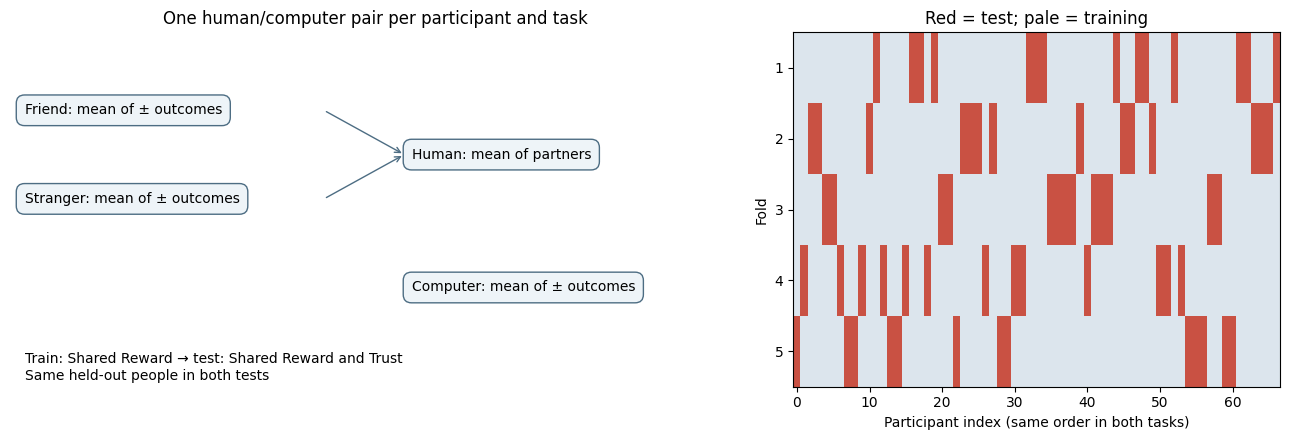

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
boxes = [(0.02, .78, "Friend: mean of ± outcomes"), (0.02, .53, "Stranger: mean of ± outcomes"),
         (.55, .655, "Human: mean of partners"), (.55, .28, "Computer: mean of ± outcomes")]
for x, y, text in boxes:
    ax.text(x, y, text, transform=ax.transAxes, fontsize=10, va="center",
            bbox=dict(boxstyle="round,pad=.6", fc="#eef4f8", ec="#4d6d83"))
for y in [.78, .53]:
    ax.annotate("", xy=(.54, .655), xytext=(.43, y), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="->", color="#4d6d83"))
ax.text(.02, .02, "Train: Shared Reward → test: Shared Reward and Trust\nSame held-out people in both tests", transform=ax.transAxes, fontsize=10)
ax.set_title("One human/computer pair per participant and task"); ax.set_axis_off()
allocation = np.zeros((N_FOLDS, len(subjects)), dtype=int)
for fold, (_, test) in enumerate(folds):
    allocation[fold, test] = 1
axes[1].imshow(allocation, aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#dce5ed", "#c95143"]), vmin=0, vmax=1)
axes[1].set(xlabel="Participant index (same order in both tasks)", ylabel="Fold",
            yticks=range(N_FOLDS), yticklabels=range(1, N_FOLDS + 1), title="Red = test; pale = training")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "workflow_folds.png", dpi=160); plt.show()

## 6. Read the performance correctly

We score **paired ordering accuracy**: is the human map's decoder score greater than the same person's computer score? It is not the same as threshold-based single-map accuracy. Positive margins indicate the intended human > computer ordering. Ties count as incorrect, as specified here.

The intervals below resample people, retaining their two target-task predictions together. They describe variation in the fixed out-of-fold predictions; they omit the additional uncertainty of refitting classifiers. A 50% reference line is not a significance test. Full participant-label permutations would need to refit the complete evaluation.

,evaluation,n,paired_ordering_accuracy,ci_low,ci_high,data_mode
0,SR → SR,67,0.805970,0.701493,0.895522,public
1,SR → Trust,67,0.880597,0.805597,0.955224,public


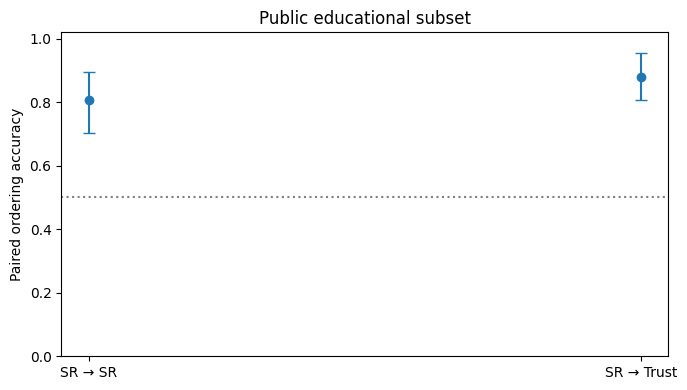

In [9]:
correct = (predictions > 0).astype(float)
rng = np.random.default_rng(SEED + 1)
bootstrap_ids = rng.integers(0, len(subjects), size=(2000, len(subjects)))
boot = correct[bootstrap_ids].mean(axis=1)
limits = np.quantile(boot, [0.025, 0.975], axis=0)
performance = pd.DataFrame({"evaluation": ["SR → SR", "SR → Trust"], "n": len(subjects),
    "paired_ordering_accuracy": correct.mean(axis=0), "ci_low": limits[0], "ci_high": limits[1],
    "data_mode": MODE})
display(performance)
fig, ax = plt.subplots(figsize=(7, 4))
values = performance.paired_ordering_accuracy.to_numpy()
ax.errorbar(np.arange(2), values, yerr=np.stack([values - limits[0], limits[1] - values]), fmt="o", capsize=4)
ax.axhline(0.5, color="gray", ls=":")
ax.set(xticks=np.arange(2), xticklabels=performance.evaluation, ylim=(0, 1.02),
       ylabel="Paired ordering accuracy", title=LABEL)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "performance.png", dpi=150)
plt.show()

### Look beyond the average accuracy

Each dot is one participant, predicted by a model trained on other people. A positive margin means human scored above computer. The zero lines divide successful and reversed orderings; their distance is not a calibrated probability. Colors identify folds, whose training sets overlap. The paired plots help reveal heterogeneity that one accuracy value conceals.

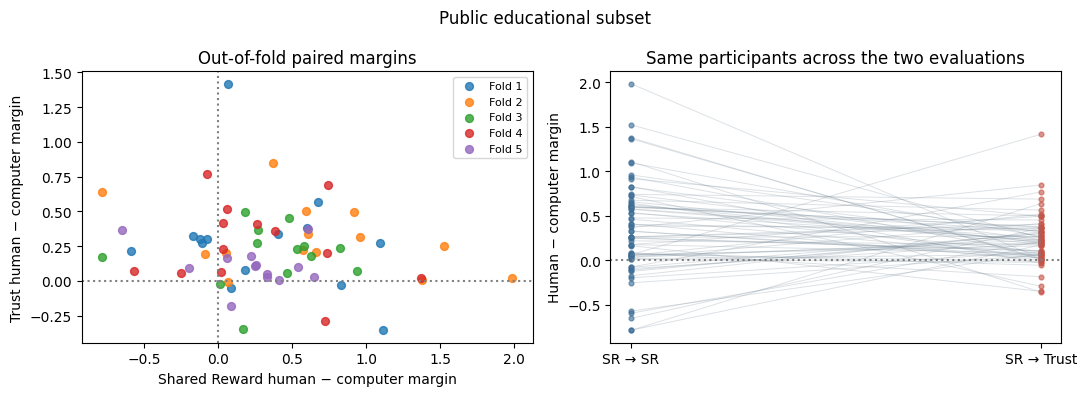

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for fold in range(1, N_FOLDS + 1):
    keep = fold_for_person == fold
    axes[0].scatter(predictions[keep, 0], predictions[keep, 1], s=32, alpha=.8, label=f"Fold {fold}")
axes[0].axhline(0, color="gray", ls=":"); axes[0].axvline(0, color="gray", ls=":")
axes[0].set(xlabel="Shared Reward human − computer margin", ylabel="Trust human − computer margin",
            title="Out-of-fold paired margins")
axes[0].legend(fontsize=8)
order = np.argsort(predictions[:, 1], kind="stable")
for person in order:
    axes[1].plot([0, 1], predictions[person], color="#708494", alpha=.24, lw=.7)
for target, color in enumerate(["#376b96", "#c95143"]):
    axes[1].scatter(np.full(len(subjects), target), predictions[:, target], s=12, color=color, alpha=.6)
axes[1].axhline(0, color="gray", ls=":")
axes[1].set(xticks=[0, 1], xticklabels=["SR → SR", "SR → Trust"], ylabel="Human − computer margin",
            title="Same participants across the two evaluations")
fig.suptitle(LABEL); fig.tight_layout(); fig.savefig(OUTPUT_DIR / "participant_margins.png", dpi=160); plt.show()
pd.DataFrame({"participant_index": np.arange(len(subjects)), "fold": fold_for_person,
              "sr_margin": predictions[:, 0], "trust_margin": predictions[:, 1]}).to_csv(OUTPUT_DIR / "paired_margins.csv", index=False)

## 7. Participant-blocked permutation test

The bootstrap interval and permutation test answer different questions. The interval describes sampling variation in the fixed predictions. Here the null asks whether human/computer labels are exchangeable within participants. Each permutation independently swaps those two labels for each person, applies **the same swap in both tasks**, refits all five Shared Reward models, and evaluates against the swapped labels of the held-out people. Folds and all preprocessing choices stay fixed. We do not shuffle a finished prediction vector.

To make 999 refits practical in a browser session, we represent each fold in an **orthonormal basis of its training maps**. A linear L2-regularized classifier has its solution in that training span. Keeping all numerically nonzero dimensions therefore preserves the model; this is not variance-based feature selection. The test maps are projected using training maps only. The check below requires agreement with the original full-voxel fit before permutations can run. Solver tolerance can produce tiny margin differences.

The two displayed tests form one family. We report both uncorrected and maximum-statistic familywise p-values, with the `+1` correction: `(1 + null values ≥ observed) / (1 + 999)`. The smallest possible p-value is .001. The exact binomial interval for the null exceedance probability and the approximate Monte Carlo standard error describe the finite randomization count; it does not replace uncertainty across participants. No model or mask is chosen from these results.

In [11]:
def svm():
    return LinearSVC(C=C, dual=True, tol=1e-4, max_iter=100000, random_state=SEED)

def training_span(training, targets):
    """Retain the complete numerical row span; construct the basis from training only."""
    a = np.asarray(training, dtype=np.float64)
    eigenvalues, u = np.linalg.eigh(a @ a.T)
    tolerance = np.finfo(float).eps * max(a.shape) * eigenvalues[-1]
    positive = eigenvalues > tolerance
    assert positive.any(), "No nonzero training dimensions."
    root = np.sqrt(eigenvalues[positive]); u = u[:, positive]
    return u * root, [((np.asarray(b, dtype=np.float64) @ a.T) @ u) / root for b in targets]

def permuted_accuracy(compressed_folds, flips):
    """One coherent participant-level relabeling, with a complete CV refit."""
    correct_count = np.zeros(2, dtype=int); largest_iteration = 0
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        for train, test, a, targets in compressed_folds:
            labels = (np.tile([1, -1], (len(train), 1)) * flips[train, None]).ravel()
            model = svm().fit(a, labels)
            largest_iteration = max(largest_iteration, int(model.n_iter_))
            for task, b in enumerate(targets):
                scores = model.decision_function(b).reshape(-1, 2)
                paired = (scores[:, 0] - scores[:, 1]) * flips[test]
                correct_count[task] += np.count_nonzero(paired > 0)
    return correct_count / len(flips), largest_iteration

compressed_folds = []; reduced_predictions = np.zeros_like(predictions)
for train, test in folds:
    a, targets = training_span(X[train, 0].reshape(-1, X.shape[-1]),
                              [X[test, target].reshape(-1, X.shape[-1]) for target in range(2)])
    compressed_folds.append((train, test, a, targets))
    model = svm().fit(a, np.tile([1, -1], len(train)))
    for task, b in enumerate(targets):
        scores = model.decision_function(b).reshape(-1, 2)
        reduced_predictions[test, task] = scores[:, 0] - scores[:, 1]
np.testing.assert_allclose(reduced_predictions, predictions, atol=2e-3, rtol=2e-3)
assert np.array_equal(reduced_predictions > 0, predictions > 0), "Ordering differs: stop before permutations."
print("Full-voxel and training-span orderings agree; maximum margin difference:",
      float(np.abs(reduced_predictions - predictions).max()))
print("Retained training dimensions:", [item[2].shape[1] for item in compressed_folds])

Full-voxel and training-span orderings agree; maximum margin difference: 2.1094237467877974e-14
Retained training dimensions: [106, 106, 108, 108, 108]


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


[Parallel(n_jobs=4)]: Done  68 tasks      | elapsed:    2.2s


[Parallel(n_jobs=4)]: Done 999 out of 999 | elapsed:    4.8s finished


,evaluation,n,observed_accuracy,permutations,null_mean,exceedances,p_uncorrected,p_familywise_two_tests,null_exceedance_probability_ci95_low,null_exceedance_probability_ci95_high,mc_standard_error_approx
0,SR → SR,67,0.805970,999,0.500276,0,0.001,0.001,0.0,0.003686,0.000707
1,SR → Trust,67,0.880597,999,0.501845,0,0.001,0.001,0.0,0.003686,0.000707


999 complete CV refits in 4.9 s; maximum solver iterations: 51 / 100000


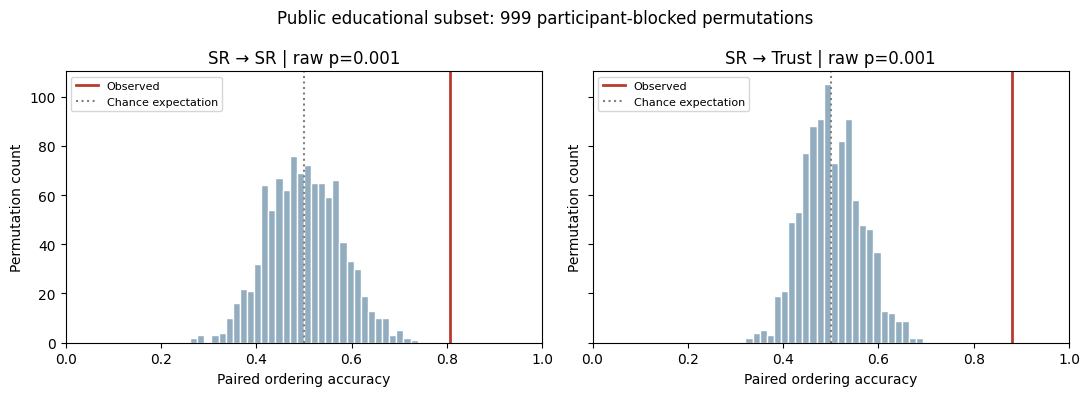

In [12]:
permutation_started = time.perf_counter()
flips = np.random.default_rng(SEED + 2).choice([-1, 1], size=(N_PERMUTATIONS, len(subjects)))
with parallel_config(backend="loky", n_jobs=N_WORKERS, inner_max_num_threads=1):
    randomized = Parallel(verbose=1)(delayed(permuted_accuracy)(compressed_folds, swap) for swap in flips)
null = np.asarray([item[0] for item in randomized])
observed = correct.mean(axis=0)
exceedances = (null >= observed).sum(axis=0)
family_exceedances = (null.max(axis=1)[:, None] >= observed).sum(axis=0)
permutation_results = pd.DataFrame({"evaluation": performance.evaluation, "n": len(subjects),
    "observed_accuracy": observed, "permutations": N_PERMUTATIONS, "null_mean": null.mean(axis=0),
    "exceedances": exceedances, "p_uncorrected": (exceedances + 1) / (N_PERMUTATIONS + 1),
    "p_familywise_two_tests": (family_exceedances + 1) / (N_PERMUTATIONS + 1)})
# Jeffreys-smoothed exceedance probability gives a finite MC error estimate even for zero exceedances.
mc_probability = (exceedances + .5) / (N_PERMUTATIONS + 1)
from scipy.stats import binomtest
mc_intervals = [binomtest(int(k), N_PERMUTATIONS).proportion_ci() for k in exceedances]
permutation_results["null_exceedance_probability_ci95_low"] = [ci.low for ci in mc_intervals]
permutation_results["null_exceedance_probability_ci95_high"] = [ci.high for ci in mc_intervals]
permutation_results["mc_standard_error_approx"] = np.sqrt(mc_probability * (1 - mc_probability) / N_PERMUTATIONS)
permutation_seconds = time.perf_counter() - permutation_started
permutation_results.to_csv(OUTPUT_DIR / "permutation_results.csv", index=False)
np.savez_compressed(OUTPUT_DIR / "permutation_null.npz", accuracies=null, seed=SEED + 2)
display(permutation_results)
print(f"{N_PERMUTATIONS} complete CV refits in {permutation_seconds:.1f} s; "
      f"maximum solver iterations: {max(item[1] for item in randomized)} / 100000")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
bins = np.arange(-.5, len(subjects) + 1.5) / len(subjects)
for target, ax in enumerate(axes):
    ax.hist(null[:, target], bins=bins, color="#92adbf", edgecolor="white")
    ax.axvline(observed[target], color="#b83b32", lw=2, label="Observed")
    ax.axvline(.5, color="gray", ls=":", label="Chance expectation")
    ax.set(xlim=(0, 1), xlabel="Paired ordering accuracy", ylabel="Permutation count",
           title=f"{performance.evaluation.iloc[target]} | raw p={permutation_results.p_uncorrected.iloc[target]:.3f}")
    ax.legend(fontsize=8)
fig.suptitle(f"{LABEL}: {N_PERMUTATIONS} participant-blocked permutations")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "permutations.png", dpi=160); plt.show()

## 8. Coefficients and forward patterns

A coefficient weights a voxel in the classifier's decision rule. Correlated voxels can have coefficients that are small, unstable or opposite in sign to their individual association with the decoded label. A Haufe-style forward pattern describes covariance between training features and decoder scores, divided by the score variance. It helps interpretation but is not a causal importance measure or a regional significance test.

These are means of five **overlapping training-fold** maps. Positive values align with higher human scores; negative values align with computer scores. We show six axial planes at predefined MNI z coordinates, with separate symmetric color scales clipped at each map's 99th absolute percentile **for display only**. No voxel is removed from fitting and no statistical threshold is applied. Maps from a small teaching subset can look different from full research-sample maps; do not change analysis choices to make them look stronger.

The anatomical underlay is retrieved separately from TemplateFlow under its upstream terms. It is not part of the CC0 Zenodo archive. Slice labels are MNI coordinates, not inferred anatomical region assignments. R marks the participant's right (neurological display).

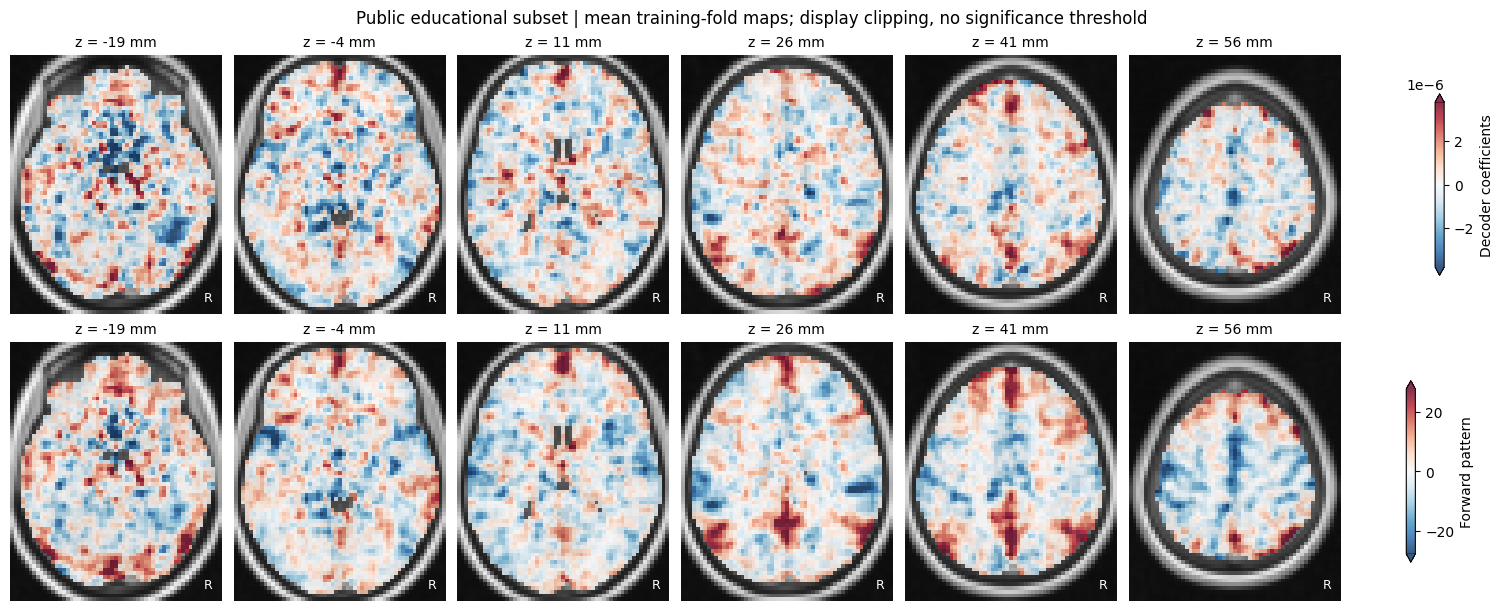

In [13]:
if MODE == "public":
    anatomy_url = "https://templateflow.s3.amazonaws.com/tpl-MNI152NLin6Asym/tpl-MNI152NLin6Asym_res-02_T1w.nii.gz"
    anatomy_sha = "2a814da50173599a857d96246dc057d548072bd6dffa499f75724dbad20792b1"
    anatomy_path = DATA_DIR / f"anatomy-{anatomy_sha}.nii.gz"
    if not anatomy_path.exists():
        with urllib.request.urlopen(anatomy_url, timeout=120) as response:
            content = response.read(5_000_001)
        assert len(content) <= 5_000_000, "Unexpected anatomy download size."
        assert hashlib.sha256(content).hexdigest() == anatomy_sha
        anatomy_path.write_bytes(content)
    assert sha256(anatomy_path) == anatomy_sha
    from nibabel.processing import resample_from_to
    anatomy = resample_from_to(nib.load(anatomy_path), (reference.shape, reference.affine), order=1)
else:
    anatomy = nib.Nifti1Image(mask.astype("float32"), reference.affine)
background = nib.as_closest_canonical(anatomy).get_fdata()
z_coordinates = [-20, -5, 10, 25, 40, 55]  # Set before viewing the maps.
fig, axes = plt.subplots(2, len(z_coordinates), figsize=(15, 6), layout="constrained")
for row, (values, title) in enumerate(zip([np.mean(weights, axis=0), np.mean(forward_patterns, axis=0)],
                                        ["Decoder coefficients", "Forward pattern"])):
    volume = np.zeros(reference.shape, dtype="float32"); volume[mask] = values
    image = nib.as_closest_canonical(nib.Nifti1Image(volume, reference.affine))
    data = image.get_fdata()
    canonical_mask = nib.as_closest_canonical(nib.Nifti1Image(mask.astype("uint8"), reference.affine)).get_fdata() > 0
    limit = float(np.quantile(np.abs(values), .99)); assert limit > 0
    for column, z in enumerate(z_coordinates):
        # Canonical image axes are aligned to RAS; nearest voxel to the specified MNI plane.
        k = int(np.clip(round(nib.affines.apply_affine(np.linalg.inv(image.affine), [0, 0, z])[2]), 0, data.shape[2] - 1))
        ax = axes[row, column]
        ax.imshow(background[:, :, k].T, origin="lower", cmap="gray", vmin=0, vmax=np.quantile(background, .99))
        plane = np.ma.masked_where(~canonical_mask[:, :, k].T, data[:, :, k].T)
        view = ax.imshow(plane, origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit, alpha=.8)
        ax.text(.92, .05, "R", color="white", transform=ax.transAxes, fontsize=9)
        actual_z = nib.affines.apply_affine(image.affine, [0, 0, k])[2]
        ax.set_title(f"z = {actual_z:.0f} mm", fontsize=10); ax.set_axis_off()
    fig.colorbar(view, ax=axes[row].tolist(), shrink=.7, label=title, extend="both")
fig.suptitle(LABEL + " | mean training-fold maps; display clipping, no significance threshold")
fig.savefig(OUTPUT_DIR / "patterns.png", dpi=180); plt.show()

## 9. What can we conclude?

- In synthetic mode, this verifies the workflow only; simulated accuracy says nothing about human social processing.
- In public mode, transfer would demonstrate prediction across these particular task contrasts in held-out tutorial participants. It would not by itself establish an abstract or uniquely social representation.
- Partner faces, relational context, task-related deactivation and other shared features can contribute to decoding. The tutorial does not resolve all such explanations.
- Tutorial analyses must not be fed back into selection of the paper's frozen signature or claims about independent validation.

**Exercises:** explain why random map-wise splits leak participant information; identify what changes when averaging outcome valence; compare the interpretations of coefficients and forward patterns; propose a future independent validation test without accessing reserved samples.

Permutation evidence is conditional on within-participant label exchangeability and the fixed analysis. Cross-task prediction alone does not separate social context from every other shared task feature. Confidence intervals omit training-refit uncertainty; the fold maps are not independent replications.


## 10. Record the environment and runtime

Record `watermark`, the Neurodesktop image, the module audit and the exact Python packages. The notebook has been executed locally and in an isolated kernel on Neurodesk Play, using Neurodesktop **2026-10-07** with Python **3.13.15**. The Play run verified all 804 map checksums and reproduced the local paired accuracies and permutation results. No FSL application module was needed or loaded.

A measured cached-data Play execution took approximately **28 seconds** including fresh-kernel startup; its 999 permutation refits took approximately **7 seconds** using four workers. First-run downloads and environment setup take additional time. These are observations from one session, not runtime guarantees. The record below describes the current execution; peak memory was not separately measured. Jacob and Riccardo should still review the teaching content and independently reproduce the example before submission.

In [14]:
if importlib.util.find_spec("watermark") is not None:
    get_ipython().run_line_magic("load_ext", "watermark")
    get_ipython().run_line_magic("watermark", "--iversions")
else:
    print("Draft environment: watermark unavailable; install the requirements before submission.")
versions = {package: importlib.metadata.version(package) for package in
            ("numpy", "pandas", "scikit-learn", "nibabel", "matplotlib", "scipy", "joblib", "threadpoolctl", "ipykernel")}
record = {"mode": MODE, "python": platform.python_version(), "packages": versions,
    "neurodesktop_image": IMAGE_VERSION, "module_audit": MODULE_AUDIT,
    "n": len(subjects), "input_map_files": len(manifest), "masked_voxels": int(mask.sum()),
    "recorded_compressed_map_bytes": int(manifest.byte_size.sum()), "feature_array_bytes": int(X.nbytes),
    "permutations": N_PERMUTATIONS, "permutation_seconds": permutation_seconds,
    "max_permutation_solver_iterations": max(item[1] for item in randomized),
    "full_vs_span_max_margin_difference": float(np.abs(reduced_predictions - predictions).max()),
    "paired_accuracies": correct.mean(axis=0).tolist(),
    "permutation_p_uncorrected": permutation_results.p_uncorrected.tolist(),
    "permutation_p_familywise": permutation_results.p_familywise_two_tests.tolist(),
    "elapsed_seconds": time.perf_counter() - STARTED, "real_public_data_used": MODE == "public"}
print(json.dumps(record, indent=2))
(OUTPUT_DIR / "execution_summary.json").write_text(json.dumps(record, indent=2) + "\n")
performance.to_csv(OUTPUT_DIR / "performance.csv", index=False)
print("Completed:", LABEL)

numpy        : 2.1.3
threadpoolctl: 3.7.0
pandas       : 2.2.3
nibabel      : 5.3.2
scipy        : 1.15.3
platform     : 1.0.8
json         : 2.0.9
sklearn      : 1.6.1
joblib       : 1.6.0
IPython      : 9.17.1
matplotlib   : 3.10.0

{
  "mode": "public",
  "python": "3.13.5",
  "packages": {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "nibabel": "5.3.2",
    "matplotlib": "3.10.0",
    "scipy": "1.15.3",
    "joblib": "1.6.0",
    "threadpoolctl": "3.7.0",
    "ipykernel": "6.29.5"
  },
  "neurodesktop_image": {},
  "module_audit": "ml unavailable: outside the Neurodesk module shell",
  "n": 67,
  "input_map_files": 804,
  "masked_voxels": 84479,
  "recorded_compressed_map_bytes": 309712382,
  "feature_array_bytes": 90561488,
  "permutations": 999,
  "permutation_seconds": 4.853475959011121,
  "max_permutation_solver_iterations": 51,
  "full_vs_span_max_margin_difference": 2.1094237467877974e-14,
  "paired_accuracies": [
    0.8059701492537313,
    0